# Figure 2: EnsIOL evolution for synthetic test case 14

Runs EnsIOL on one synthetic test case and plots the ensemble of resistivity estimates at successive stages of catalog augmentation. Te notebook starts from the prior catalog and the stored observation.

**What each row shows.** A single backward EnsCGP update (500 nearest members in data space) against the catalog as it stood after the given EnsIOL iteration. Row 0 is the original catalog. The catalog only grows by appending, so every stage is rebuilt exactly from the original catalog plus the additions.

**Metrics in the row titles.** RMS error of the ensemble mean against the true log10 resistivity, and nRMS of the mean of the members' simulated responses (the manuscript's conventions; set in `ScoringConfig`).

**Files needed** in `data/kilauea/`: the prior catalog (`kilauea_1d_{ResModels,AppRes,Phase}_prior.txt`, rebuilt by `scripts/build_prior_catalog.py`), the grids, and the test set (`kilauea_1d_*_test.txt`).

Running time is about a minute or two on a laptop.

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import ensiol
from ensiol import ExperimentContext, EnsIOLConfig, ScoringConfig

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO / "data" / "kilauea"        # prior catalog, grids and the synthetic test set
FIG_DIR = REPO / "figures"                  # figures are written here
FIG_DIR.mkdir(exist_ok=True)

## 1. Settings

In [2]:
SAMPLE_IDX = 14

# Which EnsIOL iterations to show as rows. None = N_ROWS evenly spaced from the
# original catalog (iteration 0) to the last iteration that added members.
ROW_ITERS = None
N_ROWS = 5

# Manuscript conventions
SCORING = ScoringConfig(exclude_halfspace=True, nrms_convention="MoR")
OUT_BASENAME = f"fig2_evolution_sample_{SAMPLE_IDX:03d}"

## 2. Run EnsIOL on the test case

In [3]:
ctx = ExperimentContext.from_data_dir(str(DATA_DIR), with_test=True, scoring=SCORING)
case = ctx.test.case(SAMPLE_IDX)
obs = case.observation
seed = ctx.config.base_seed + SAMPLE_IDX          # same seed rule as the cluster run

run = ctx.augment(obs, seed, truth_linear=case.truth_linear)
print(f"sample {SAMPLE_IDX}: {run.n_added} members added in {len(run.growth.history)} iterations "
      f"({run.growth.exit_reason}), {run.n_leak_removed} duplicate(s) of the truth removed from the prior, "
      f"{run.runtime_s:.0f} s")

prior catalog: 10000 members | 54 layers | 37 freqs | d_min = 1.0695
sample 14: 1931 members added in 52 iterations (growth_stall), 0 duplicate(s) of the truth removed from the prior, 36 s


## 3. The estimate at each stage

Each stage is one backward EnsCGP update on the catalog snapshot, with the same seed as the run.

In [4]:
rows = run.evolution_rows(iterations=ROW_ITERS, n_rows=N_ROWS)
ctx.scorer.annotate_rows(rows, obs, case.truth_log10)

print(f"{'iter':>5} {'added':>6} {'RMS (excl. half-space)':>24} {'nRMS (MoR)':>11} {'nRMS (RoM)':>11}")
for r in rows:
    print(f"{r['iteration']:5d} {r['n_added']:6d} {r['RMS_excl']:24.3f} {r['nRMS_MoR']:11.3f} {r['nRMS_RoM']:11.3f}")

 iter  added   RMS (excl. half-space)  nRMS (MoR)  nRMS (RoM)
    0      0                    0.960       3.622       3.867
   13    650                    0.693       1.415       1.442
   26   1300                    0.527       1.105       1.129
   38   1848                    0.357       1.041       1.060
   51   1931                    0.346       1.040       1.057


## 4. Figure

All styling lives in `PublicationStyle` (sizes in inches and points: 7.16 in is full width in a two-column IEEE journal). Use `STYLE.but(...)` to change a setting and rerun only this cell. `columns` selects and orders the panels per row; `title_template` fields are `{it}`, `{added}`, `{rms}`, `{nrms}`.

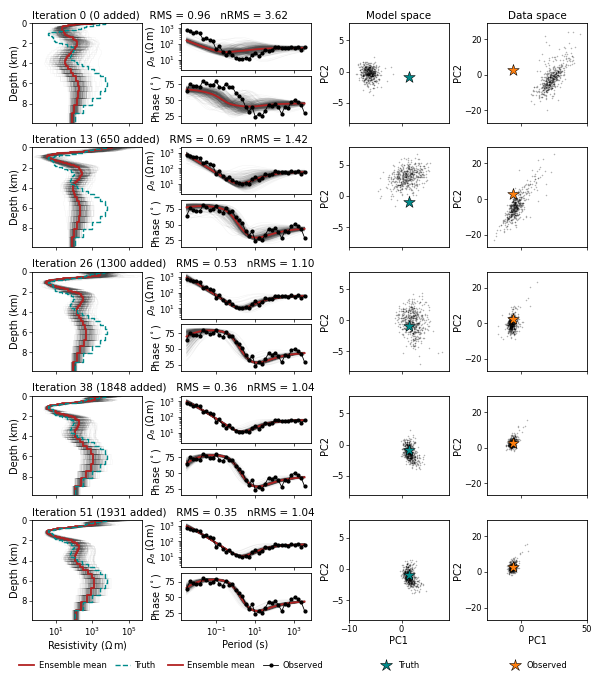

saved figures/fig2_evolution_sample_014.pdf, figures/fig2_evolution_sample_014.png


In [5]:
from ensiol.plotting import PublicationStyle, plot_evolution_publication

STYLE = PublicationStyle()          # defaults reproduce the manuscript figure
fig = plot_evolution_publication(rows, obs, ctx.grid.depths, ctx.whitener.ref_std, ctx.config.noise,
                                 case.truth_linear, STYLE, SCORING)
for ext in STYLE.formats:
    fig.savefig(FIG_DIR / f"{OUT_BASENAME}.{ext}", dpi=STYLE.dpi, bbox_inches="tight", pad_inches=0.02)
plt.show()
print("saved", ", ".join(f"figures/{OUT_BASENAME}.{e}" for e in STYLE.formats))

## Notes

* The estimate shown is a single backward EnsCGP update. The forward/backward correction exists only inside the EnsIOL growth loop.
* The responses in the data-space panels are the true forward responses of the updated members.
* The half-space is not drawn in the resistivity panels (it has no finite thickness) but is included in the ensemble and in the model-space PCA.
* PCA bases are fitted once on all rows together (plus the truth or the observation), so positions are comparable between rows.
* To choose rows by hand, set e.g. `ROW_ITERS = [0, 5, 13, 26, 51]`.